In [ ]:
import os 
import sys
from dotenv import load_dotenv
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
import keras
import tensorflow as tf 
print(tf.__version__)
print(tf.config.list_physical_devices("GPU"))

module_path = os.path.abspath(os.path.join('../../'))
if module_path not in sys.path:
    # adds the 'src' directory to the python path
    sys.path.append(module_path)

from src.utils import (
    generate_confusion, 
    generate_roc_curve, 
    plot_train_accuracy, 
    plot_train_loss, 
    get_dataset_distribution
)


2.16.1
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
load_dotenv()
dataset_path = os.getenv("DATASET_DIR")
model_path = os.getenv("MODEL_DIR")

MODEL_NAME = "CXC104.keras"
model = os.path.join(model_path, MODEL_NAME)

train_data_dir = os.path.join(dataset_path, "data04", "train")
test_data_dir = os.path.join(dataset_path, "data04", "test")
val_data_dir = os.path.join(dataset_path, "data04", "val")


# Set parameters
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

print(train_data_dir)
print(test_data_dir)
print(val_data_dir)



/Users/joshan/Documents/final-year-project/dataset/data04/train
/Users/joshan/Documents/final-year-project/dataset/data04/test
/Users/joshan/Documents/final-year-project/dataset/data04/val


In [3]:
get_dataset_distribution(
        [
          train_data_dir, 
          test_data_dir, 
          val_data_dir
        ]
    )

╒═══════════╤══════════╤═════════════╤════════════════╤═══════════╤═════════╕
│ Dataset   │   Normal │   Pneumonia │   Tuberculosis │   Unknown │   Total │
╞═══════════╪══════════╪═════════════╪════════════════╪═══════════╪═════════╡
│ Train     │     6083 │        6165 │           5924 │      1155 │   19327 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Test      │      548 │         427 │            417 │       135 │    1527 │
├───────────┼──────────┼─────────────┼────────────────┼───────────┼─────────┤
│ Val       │      274 │         213 │            207 │        67 │     761 │
╘═══════════╧══════════╧═════════════╧════════════════╧═══════════╧═════════╛


{'train': {'NORMAL': 6083,
  'PNEUMONIA': 6165,
  'TUBERCULOSIS': 5924,
  'UNKNOWN': 1155},
 'test': {'NORMAL': 548,
  'PNEUMONIA': 427,
  'TUBERCULOSIS': 417,
  'UNKNOWN': 135},
 'val': {'NORMAL': 274, 'PNEUMONIA': 213, 'TUBERCULOSIS': 207, 'UNKNOWN': 67}}

In [4]:
train_ds = tf.keras.utils.image_dataset_from_directory(
    train_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical' # Important for 3-class classification
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

val_ds = tf.keras.utils.image_dataset_from_directory(
   val_data_dir,
    color_mode='rgb',
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode='categorical'
)

Found 19326 files belonging to 4 classes.
Found 1527 files belonging to 4 classes.
Found 761 files belonging to 4 classes.


2026-05-10 15:17:35.282617: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M3
2026-05-10 15:17:35.282650: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2026-05-10 15:17:35.282665: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.92 GB
2026-05-10 15:17:35.283370: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2026-05-10 15:17:35.283389: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


In [5]:
class_names = train_ds.class_names

print("Class names:", class_names)

for i, label in enumerate(class_names):
    print(f"Index {i}: {label}")

Class names: ['NORMAL', 'PNEUMONIA', 'TUBERCULOSIS', 'UNKNOWN']
Index 0: NORMAL
Index 1: PNEUMONIA
Index 2: TUBERCULOSIS
Index 3: UNKNOWN


In [6]:
base_model = VGG16(
    input_shape=(224,224, 3), 
    weights='imagenet', 
    include_top=False # remove last layer of vgg16
)

In [7]:
# don't want to train existing layers 
base_model.trainable = False

In [8]:
data_augmentation = models.Sequential([
    
    # Flip left-right (lungs are symmetric)
    layers.RandomFlip("horizontal"),
    
    # Small rotation for positioning differences
    layers.RandomRotation(0.05),
    
    # Slight zoom to simulate distance from scanner
    layers.RandomZoom(0.1),
    
    # Small translation for patient positioning
    layers.RandomTranslation(height_factor=0.05, width_factor=0.05),
    
    # Slight contrast variation from different scanners
    layers.RandomContrast(0.1),
    
])


2026-05-10 15:17:56.009800: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


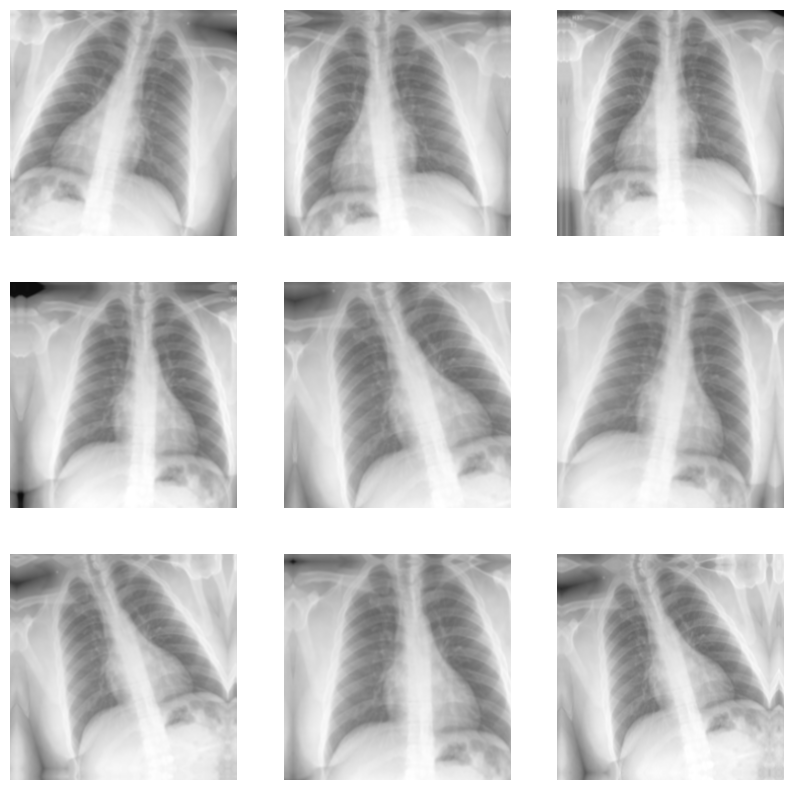

In [9]:
import matplotlib.pyplot as plt

for image, _ in train_ds.take(1):
  plt.figure(figsize=(10, 10))
  first_image = image[0]
  for i in range(9):
    ax = plt.subplot(3, 3, i + 1)
    augmented_image = data_augmentation(tf.expand_dims(first_image, 0))
    plt.imshow(augmented_image[0] / 255)
    plt.axis('off')

In [25]:
model = models.Sequential([
    data_augmentation,
    layers.Rescaling(1./255),

    base_model,
    
    layers.GlobalAveragePooling2D(),
   
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    
    layers.Dropout(0.5), # Regularization to prevent overfitting
    
    layers.Dense(4, activation='softmax')
])

In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)


model.summary()


# Train the model
history = model.fit(
    train_ds,
    validation_data=val_ds, # evaluating against val dataset
    epochs=10
)

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_3 (Rescaling)         │ (1, 224, 224, 3)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (1, 7, 7, 512)         │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (1, 512)               │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (1, 128)               │        65,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (1, 128)               │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (1, 128)               │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (1, 4)                 │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,781,380 (56.39 MB)

 Trainable params: 66,436 (259.52 KB)

 Non-trainable params: 14,714,944 (56.13 MB)

Epoch 1/10


  9/604 ━━━━━━━━━━━━━━━━━━━━ 3:34 361ms/step - accuracy: 0.2866 - loss: 2.0946

KeyboardInterrupt: 

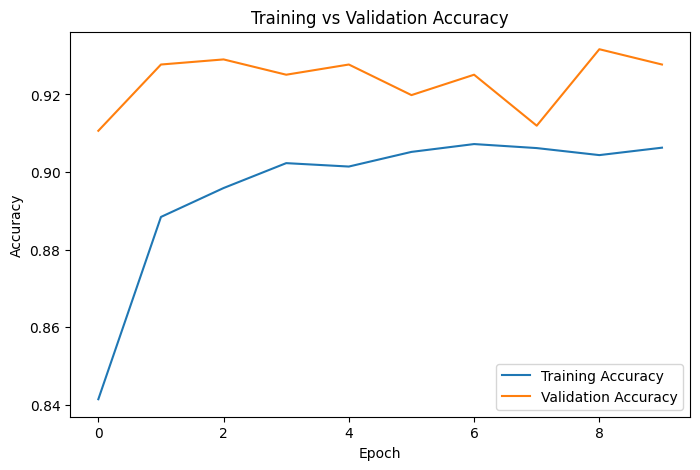

In [23]:
plot_train_accuracy(history=history)

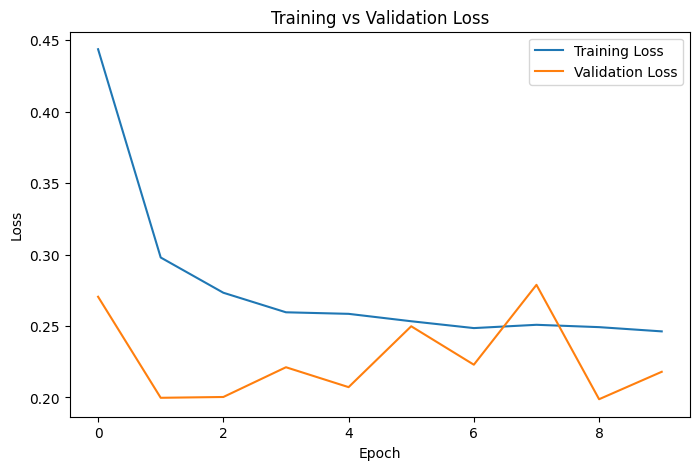

In [24]:
plot_train_loss(history=history)

In [13]:
# Save the model
model.save('CXC105.keras')
print("Model saved successfully!")

Model saved successfully!


In [20]:
# Evaludate against test data
results = model.evaluate(test_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

48/48 ━━━━━━━━━━━━━━━━━━━━ 15s 301ms/step - accuracy: 0.9064 - loss: 0.2505
Test Loss: 0.25047072768211365
Test Accuracy: 90.64%


2026-05-10 16:09:25.827417: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


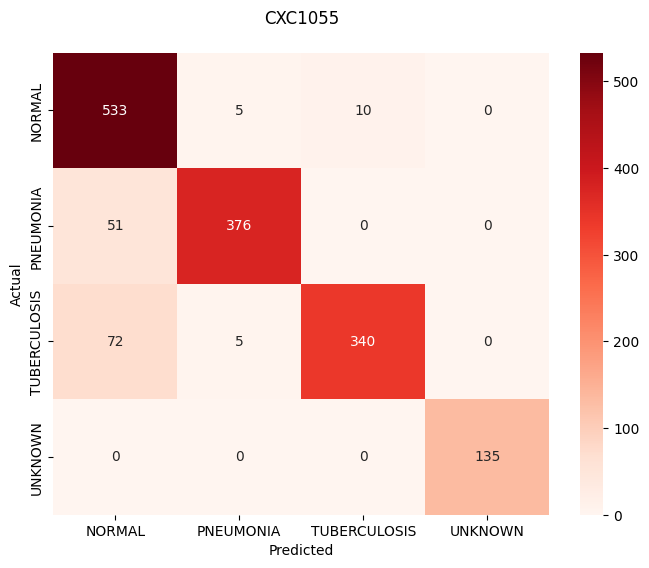

              precision    recall  f1-score   support

      NORMAL       0.81      0.97      0.89       548
   PNEUMONIA       0.97      0.88      0.92       427
TUBERCULOSIS       0.97      0.82      0.89       417
     UNKNOWN       1.00      1.00      1.00       135

    accuracy                           0.91      1527
   macro avg       0.94      0.92      0.92      1527
weighted avg       0.92      0.91      0.91      1527



In [22]:
generate_confusion(test_ds, model=model, title="CXC1055")

In [16]:
results = model.evaluate(val_ds)
print(f"Test Loss: {results[0]}")
print(f"Test Accuracy: {results[1]*100:.2f}%")

24/24 ━━━━━━━━━━━━━━━━━━━━ 8s 342ms/step - accuracy: 0.9146 - loss: 0.2307
Test Loss: 0.2306579351425171
Test Accuracy: 91.46%
